In [100]:
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split


In [5]:
cars_data = pd.read_csv("Cars.csv")

In [6]:
cars_data.shape

(81, 5)

In [7]:
cars_data.describe()

,HP,MPG,VOL,SP,WT
count,81.000000,81.000000,81.000000,81.000000,81.000000
mean,117.469136,34.422076,98.765432,121.540272,32.412577
std,57.113502,9.131445,22.301497,14.181432,7.492813
min,49.000000,12.101263,50.000000,99.564907,15.712859
25%,84.000000,27.856252,89.000000,113.829145,29.591768
50%,100.000000,35.152727,101.000000,118.208698,32.734518
75%,140.000000,39.531633,113.000000,126.404312,37.392524
max,322.000000,53.700681,160.000000,169.598513,52.997752


In [8]:
cars_data.dtypes

HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object

In [10]:
cars_data.isna().sum()

HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64

## Histogram

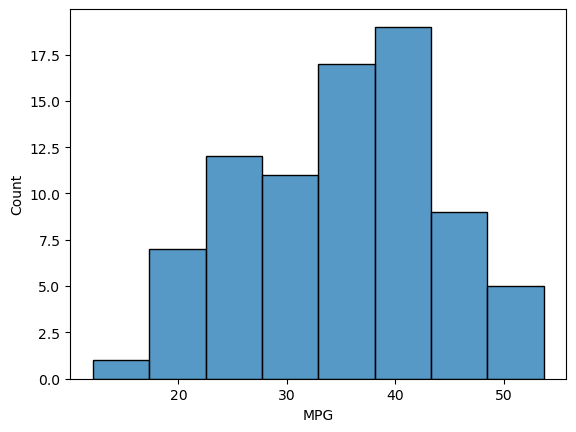

In [13]:
sns.histplot(data=cars_data, x='MPG')
plt.xlabel("MPG")
plt.ylabel("Count")
plt.show()

In [14]:
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


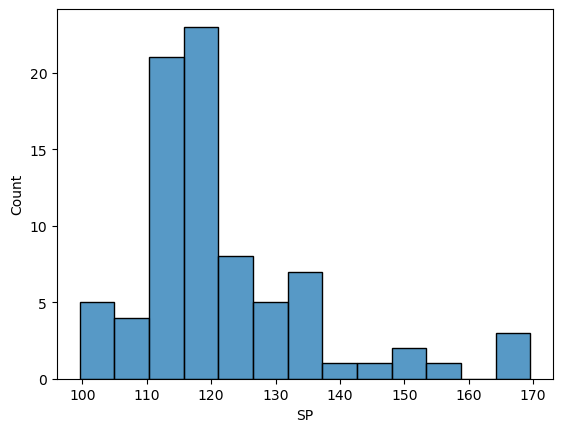

In [15]:
sns.histplot(data=cars_data, x='SP')
plt.xlabel("SP")
plt.ylabel("Count")
plt.show()

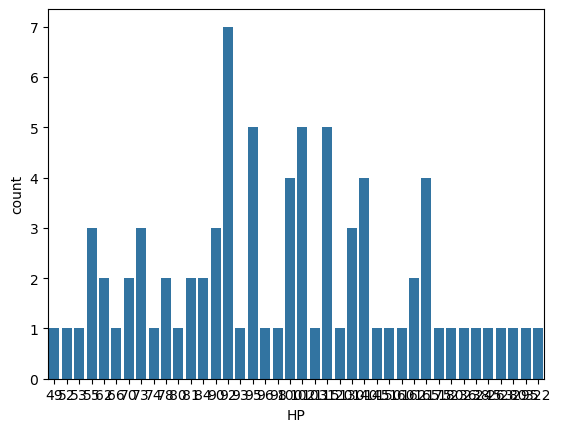

In [19]:
# countplot--> mainly used for categorical variables
# sns.countplot(data=cars_data, x="HP")
# plt.show()

In [26]:
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


## Need to check the linearity tests


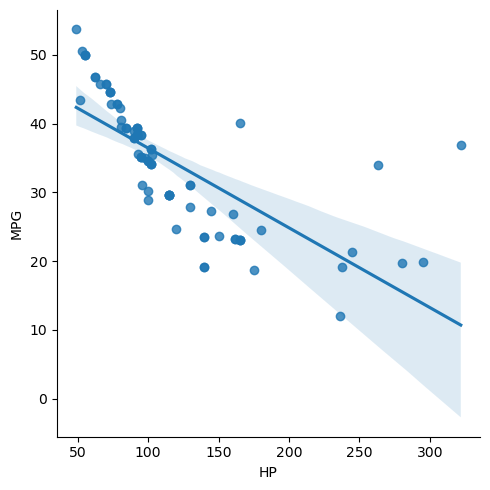

In [30]:
sns.lmplot(data=cars_data, x="HP", y="MPG")
plt.show()

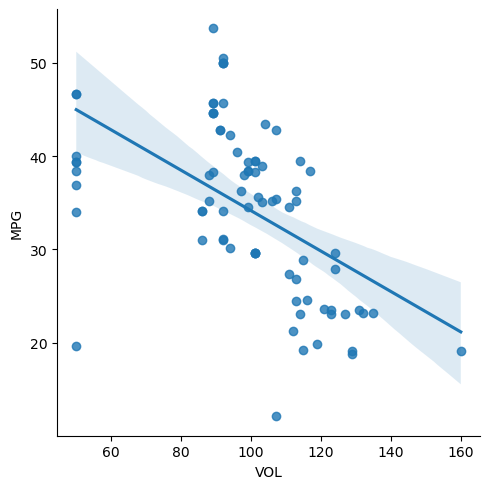

In [32]:
sns.lmplot(data=cars_data, x="VOL", y="MPG")
plt.show()

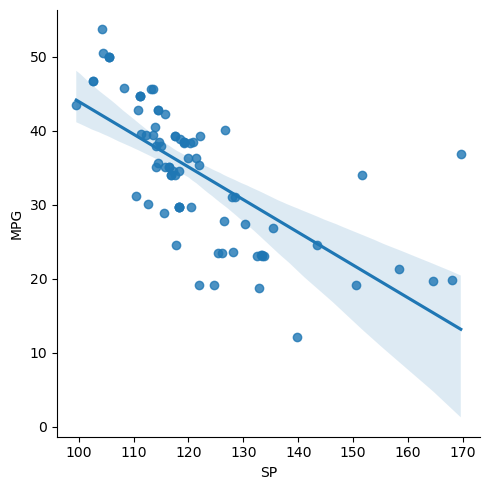

In [33]:
sns.lmplot(data=cars_data, x="SP", y="MPG")
plt.show()

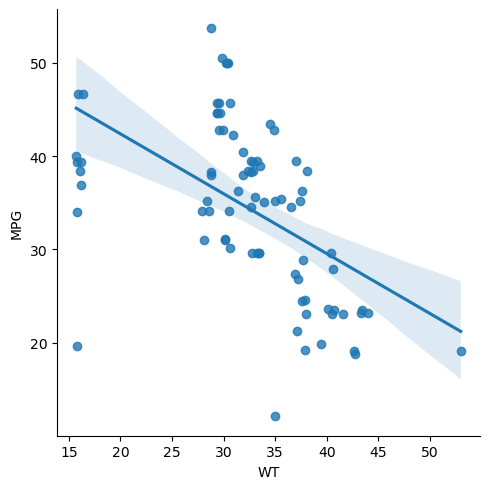

In [34]:
sns.lmplot(data=cars_data, x="WT", y="MPG")
plt.show()

## Normality Test

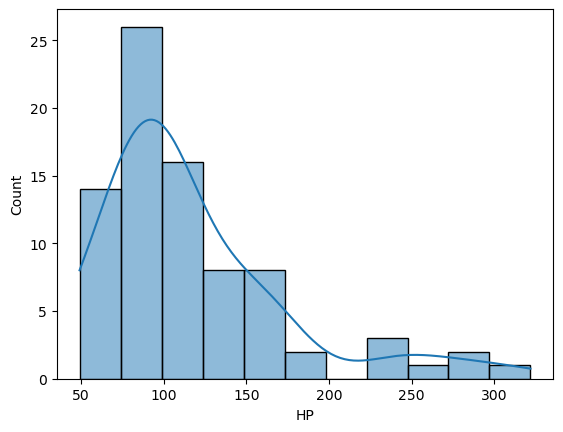

In [36]:
sns.histplot(data=cars_data, x='HP', kde=True)
plt.show()

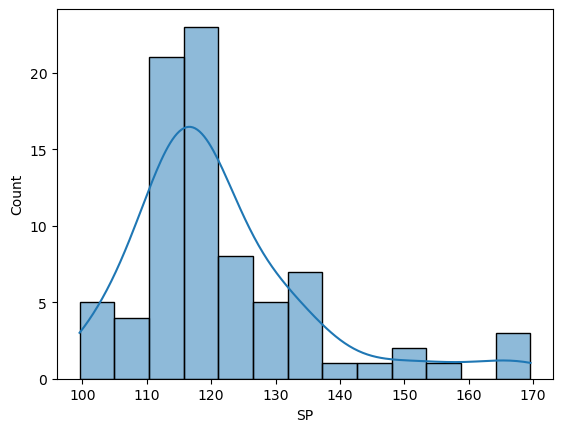

In [39]:
sns.histplot(data=cars_data, x='SP', kde=True)
plt.show()

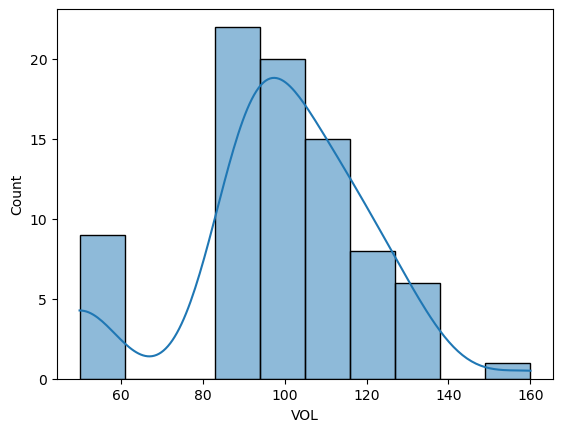

In [42]:
sns.histplot(data=cars_data, x='VOL', kde=True)
plt.show()

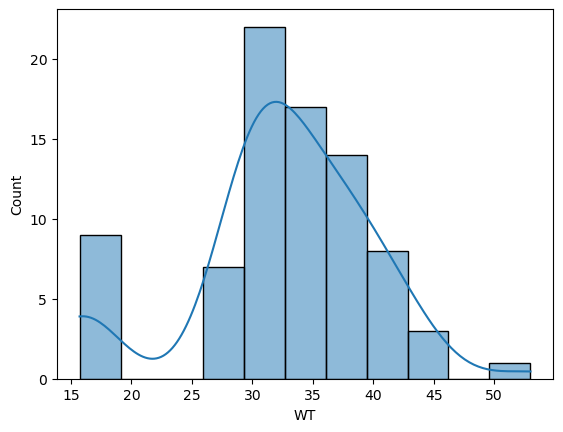

In [43]:
sns.histplot(data=cars_data, x='WT', kde=True)
plt.show()

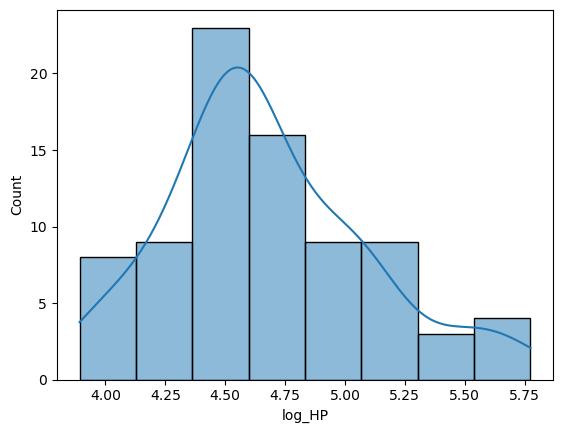

In [44]:
import numpy as np
cars_data["log_HP"] = np.log(cars_data["HP"])
sns.histplot(data=cars_data, x="log_HP", kde=True)
plt.show()

## MultiCollinearity Test

In [46]:
corr_matrix = cars_data.corr()
corr_matrix

,HP,MPG,VOL,SP,WT,log_HP
HP,1.000000,-0.725038,0.077459,0.973848,0.076513,0.963779
MPG,-0.725038,1.000000,-0.529057,-0.687125,-0.526759,-0.843451
VOL,0.077459,-0.529057,1.000000,0.102170,0.999203,0.193608
SP,0.973848,-0.687125,0.102170,1.000000,0.102439,0.944864
WT,0.076513,-0.526759,0.999203,0.102439,1.000000,0.191535
log_HP,0.963779,-0.843451,0.193608,0.944864,0.191535,1.000000


<Axes: >

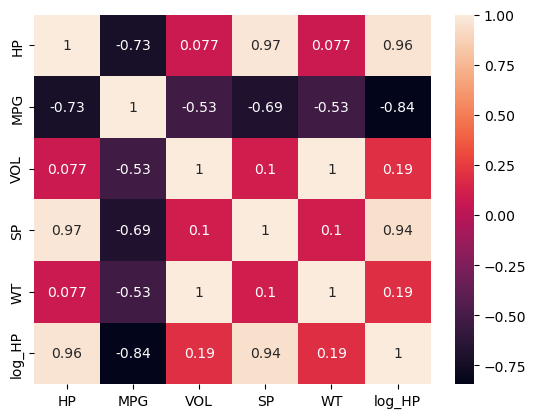

In [47]:
sns.heatmap(data=corr_matrix,annot=True)

<Axes: >

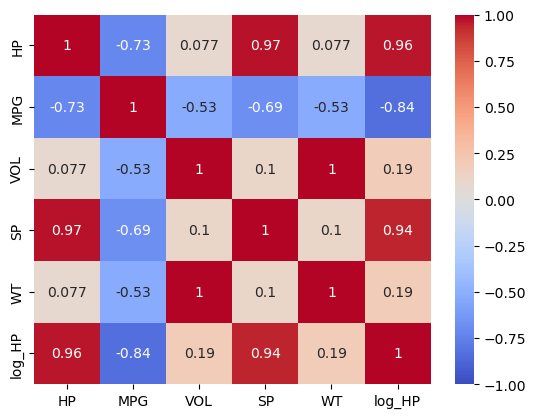

In [48]:
sns.heatmap(data=corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)

In [51]:
del cars_data["log_HP"]

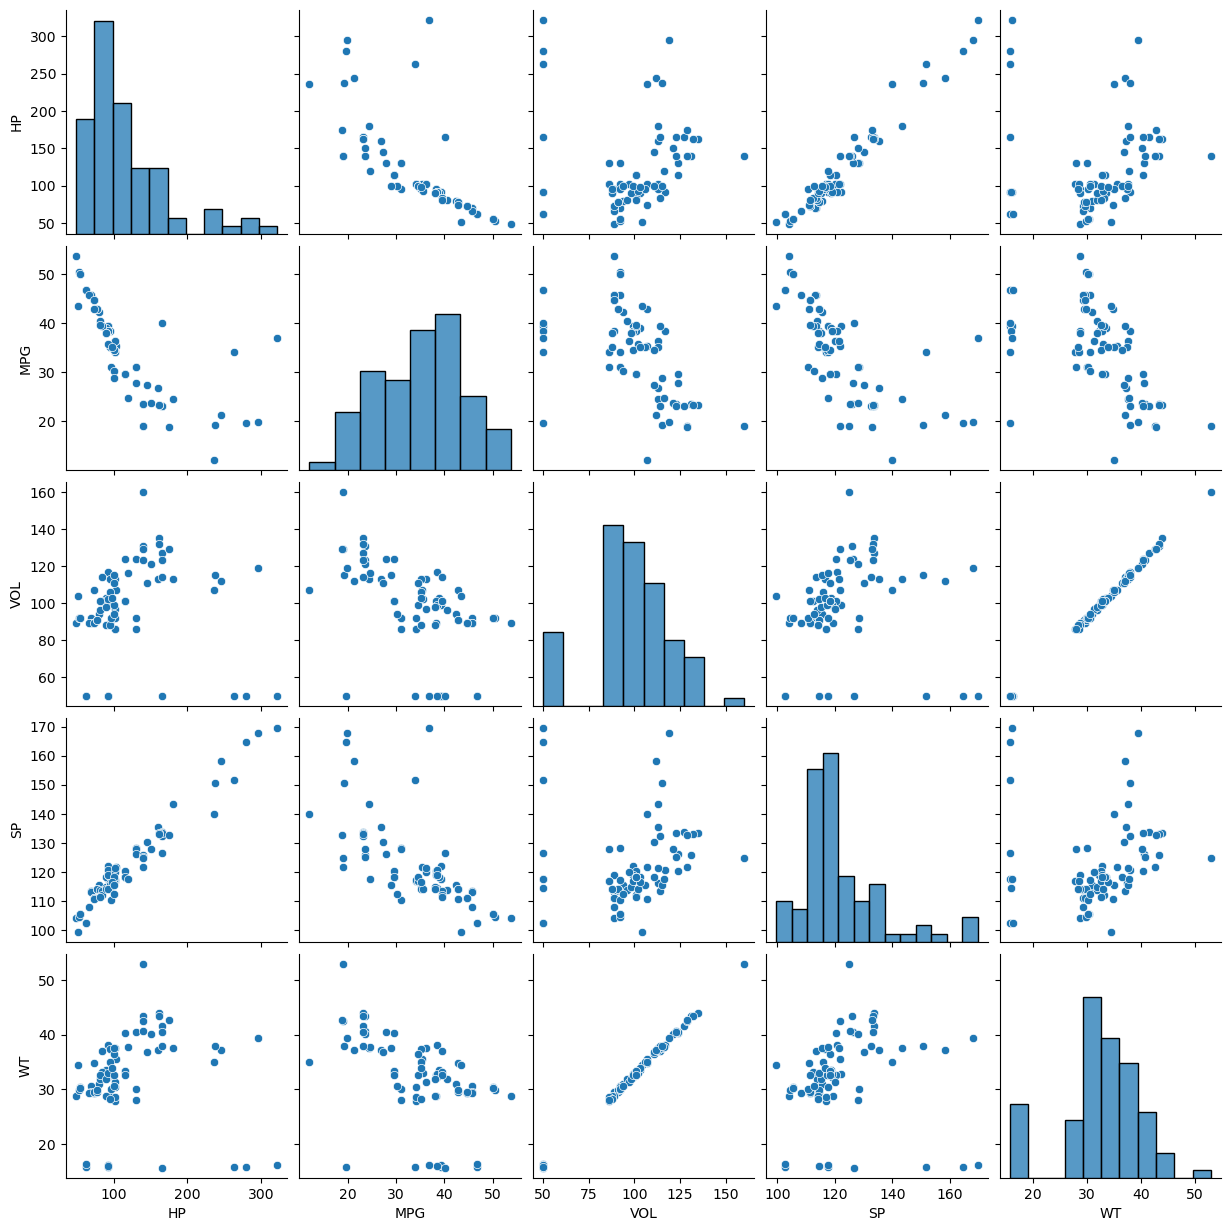

In [52]:
sns.pairplot(data=cars_data)
plt.show()

## Train and split the data

In [57]:
X = cars_data.drop("MPG", axis=1)
y = cars_data["MPG"]


y

0     53.700681
1     50.013401
2     50.013401
3     45.696322
4     50.504232
        ...    
76    36.900000
77    19.197888
78    34.000000
79    19.833733
80    12.101263
Name: MPG, Length: 81, dtype: float64

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20,shuffle=True,random_state=45)
print (X_train.shape)

(64, 4)


In [60]:
print (X_test.shape)

(17, 4)


In [62]:
print (y_train.shape)

(64,)


In [61]:
print (y_test.shape)

(17,)


In [76]:
linear_model = LinearRegression()
linear_model

LinearRegression()

## Training is done on Training data

In [75]:
linear_model.fit(X_train, y_train)

LinearRegression()

In [78]:
linear_model.intercept_

np.float64(-24.40426665535915)

In [79]:
print ("Coefficients ", dict(zip(X_train.columns, linear_model.coef_)))

Coefficients  {'HP': np.float64(-0.31158528959530457), 'VOL': np.float64(-2.4562257992029854), 'SP': np.float64(1.0276073402954218), 'WT': np.float64(6.6349995518521805)}


## Training is done on Testing data

In [84]:
linear_model.fit(X_test, y_test)

LinearRegression()

In [81]:
linear_model.intercept_

np.float64(-24.40426665535915)

In [86]:
print ("Coefficients ", dict(zip(X_test.columns, linear_model.coef_)))

Coefficients  {'HP': np.float64(-0.31158528959530457), 'VOL': np.float64(-2.4562257992029854), 'SP': np.float64(1.0276073402954218), 'WT': np.float64(6.6349995518521805)}


## Prediction on Training data

In [93]:
y_train_pred = linear_model.predict(X_train)
y_train_pred

array([41.54330392, 47.83213584, 42.77060529, 40.30324528, 38.05526199,
       30.63172876, 36.75076827, 39.62183923, 14.83093772, 41.76079292,
       43.77675472, 35.05551035, 43.88377198, 36.19268073, 35.15272537,
       40.94050078, 25.32590493, 44.01743236, 35.09182331, 29.77844771,
       26.96157763, 27.63535874, 41.27216928, 33.26636068, 43.42670743,
       25.45756586, 36.14692838, 49.48838724, 34.50191528, 33.09869629,
       41.95528574, 28.82586788, 18.77602508, 32.31356765, 38.3302823 ,
       37.24273268, 39.43116193, 41.09478118, 22.65483321, 25.54040721,
       23.12421837, 38.76858845, 42.67898688, 52.41168086, 25.36077921,
       40.83352975, 36.33109637, 33.61530143, 46.95775463, 39.66920105,
       47.44230611, 35.4365768 , 30.43277314, 38.92148699, 42.3182539 ,
       35.72124093, 44.92681634, 27.59311099, 36.7621724 , 25.40418415,
       36.99850602, 47.64967882, 31.80642118, 24.58083023])

## Prediction on Testing data

In [96]:
y_test_pred = linear_model.predict(X_test)
y_test_pred

array([37.69884261, 48.32732809, 43.32655291, 38.69056763, 36.98485517,
       43.00596055, 32.43940908, 35.2390651 , 29.72009612, 41.19303709,
       40.63079801, 33.61382926, 33.25051343, 33.77675583, 44.04700798,
       31.25271435, 35.23620322])

## Evaluation metrics

In [101]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
import statsmodels.formula.api as smf

In [103]:
mean_absolute_error(y_test, y_test_pred)

3.9405697368957617

In [104]:
mean_squared_error(y_test, y_test_pred)

23.010733228671704

In [105]:
root_mean_squared_error(y_test, y_test_pred)

4.796950409236238

In [106]:
r2_score(y_test, y_test_pred)

0.5247318155235018

In [111]:
linear_stats_model = smf.ols(formula="MPG ~ HP", data=cars_data).fit()
linear_stats_model

In [113]:
linear_stats_model.rsquared_adj.round(3)

np.float64(0.52)

ERROR! Session/line number was not unique in database. History logging moved to new session 5


In [121]:
linear_stats_model = smf.ols(formula="MPG ~ HP+VOL", data=cars_data).fit()
print (f"rsquare : {linear_stats_model.rsquared}" )
print (f"Adjusted rsquare : {linear_stats_model.rsquared_adj.round(3)}")


rsquare : 0.7506606277376422
Adjusted rsquare : 0.744


In [114]:
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099
